# Millbrook weather, June 2026

A month of daily readings from a weather diary: each day's
high and low in degrees Celsius, and the rain in millimetres.
This notebook loads the diary from `weather.csv`, works out
the shape of the month, and draws it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("weather.csv", parse_dates=["date"])
df.head()

,date,high_c,low_c,rain_mm
0,2026-06-01,24,13,0.0
1,2026-06-02,25,14,0.0
2,2026-06-03,27,15,0.0
3,2026-06-04,28,16,0.0
4,2026-06-05,26,15,2.4


## The shape of the month

Five numbers tell most of the story: how many days, the
hottest one, the average high, and how the rain fell.

In [2]:
hottest = df.loc[df["high_c"].idxmax()]
print(f"Days of readings: {len(df)}")
print(f"Hottest day: {hottest['date'].date()} at {hottest['high_c']} C")
print(f"Mean high: {df['high_c'].mean():.1f} C")
print(f"Total rain: {df['rain_mm'].sum():.1f} mm")
print(f"Rainy days (1 mm or more): {(df['rain_mm'] >= 1).sum()}")

Days of readings: 30
Hottest day: 2026-06-21 at 33 C
Mean high: 27.3 C
Total rain: 39.4 mm
Rainy days (1 mm or more): 7


## The month in one picture

Highs and lows, day by day. The gap between the two lines
is the day's swing; the hot spell in the third week and the
wet break after it are both easy to see.

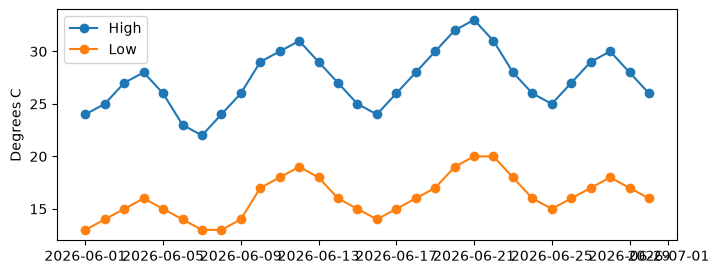

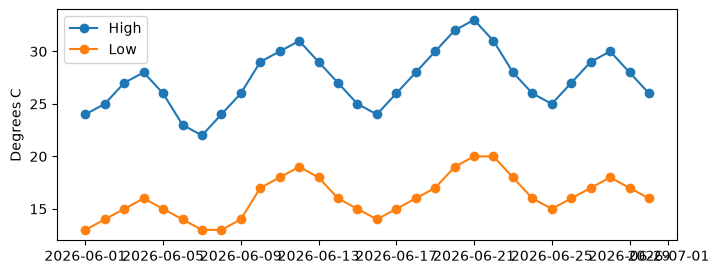

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(df["date"], df["high_c"], marker="o", label="High")
ax.plot(df["date"], df["low_c"], marker="o", label="Low")
ax.set_ylabel("Degrees C")
ax.legend()
fig

## Week by week

The same month in four rough weeks (the last one is nine
days; diaries are not tidy), averaged.

In [4]:
df["week"] = (df["date"].dt.day - 1) // 7 + 1
weekly = df.groupby("week")[["high_c", "low_c", "rain_mm"]].mean()
print(weekly.round(1).to_string())

      high_c  low_c  rain_mm
week                        
1       25.0   14.3      1.7
2       28.0   16.4      0.8
3       28.3   16.6      0.0
4       28.0   17.1      3.1
5       27.0   16.5      0.2
